In [28]:
using Pkg
Pkg.activate(".")
Pkg.add("ITensors")
Pkg.add("ITensorMPS")
include("Modules.jl")

using .FunctionTCI



  Activating project at `.`
   Resolving package versions...
  No Changes to `./Project.toml`
  No Changes to `./Manifest.toml`
   Resolving package versions...
   Installed ITensorMPS ─ v0.3.26
    Updating `./Project.toml`
  [0d1a4710] + ITensorMPS v0.3.26
    Updating `./Manifest.toml`
  [0d1a4710] + ITensorMPS v0.3.26
Precompiling project...
   2059.5 ms  ✓ ITensorMPS
   1457.4 ms  ✓ ITensorMPS → ITensorMPSHDF5Ext
   1506.9 ms  ✓ ITensorMPS → ITensorMPSChainRulesCoreExt
   1558.6 ms  ✓ ITensorMPS → ITensorMPSZygoteRulesExt
  4 dependencies successfully precompiled in 6 seconds. 508 already precompiled.


In [29]:
module RandomTarget
using LinearAlgebra, Random
export random_tt_cores_C, random_tt_function

"""
    random_tt_cores_C(Len::Int, χ::Int, phys_dims::Vector; T=Float64)

Generate a random TT (tensor train) cores_C for a chain of length `Len`, 
with local dimension 3 at each site, and maximum bond dimension `χ`.
Returns a Vector of Array{T,3} of length Len.
"""
    function random_tt_cores_C(Len::Int, χ::Int, phys_dims::Vector; T=Float64)
        # Determine TT bond dimensions: r₀=1, r₁,...,r_{Len-1}, r_L=1, all ≤ χ
        # For simplicity, set all internal bonds to χ (or 1 if Len==1)
        r = [1; fill(χ, Len-1); 1]
        cores = Vector{Array{T,3}}(undef, Len)
        for p in 1:Len
            cores[p] = randn(T, r[p], phys_dims[p], r[p+1])
        end
        # Frobenius normalization via TT inner product (no dense tensor)
        function tt_frobenius_norm(cores)
            env = ones(T, 1, 1)
            for G in cores
                _, d, rR = size(G)
                env_next = zeros(T, rR, rR)
                @inbounds for s in 1:d
                    Gs = view(G, :, s, :)
                    env_next .+= Gs' * env * Gs
                end
                env = env_next
            end
            return sqrt(env[1, 1])
        end

        norm_T = tt_frobenius_norm(cores)
        scale = norm_T == 0 ? eps(T) : norm_T^(1 / Len)

        for p in 1:Len
            cores[p] ./= scale
        end

        return cores
    end

    """
        make_random_fq(Len::Int, χ::Int, phys_dims, t::Vector{<:Function}; T=Float64)

    Generate a function fq(ϕ::AbstractVector) that evaluates a random TT function
    using random_tt_cores_C(Len, χ, phys_dims; T) and `eval_from_ttC`.
    Returns a tuple (fq, cores_C).

    NOTE: fq(ϕ) expects ϕ to be a vector of length Len, and t to be a vector of functions of length Len.
    """
    function make_random_fq(Len::Int, χ::Int, phys_dims, t::AbstractVector{<:Function}; T=Float64)
        cores_C = random_tt_cores_C(Len, χ, phys_dims; T=T)
        fq = function(x::AbstractVector{<:Real})
            @assert length(t) == length(cores_C) "Basis vector t must have length $(length(cores_C))"
            return Main.eval_from_ttC(cores_C, t, x)
        end
        return fq, cores_C
    end

    function make_random_fq_noisy(Len::Int, χ::Int, phys_dims, t;   T=Float64, delta=1e-4, seed=123)
        fq, cores_C = make_random_fq(Len, χ, phys_dims, t; T=T)
        rng = MersenneTwister(seed + 123456)  # offset to avoid correlation with main rng
        function fq_noisy(phis::AbstractVector{<:Real})
            val = fq(phis)
            noise = randn(rng) * sqrt(delta) # Gives the Normal (0,delta)
            return val + noise
        end
        return fq_noisy, fq, cores_C
    end

end # module



Main.RandomTarget

In [30]:
import TensorCrossInterpolation as TCI
using LinearAlgebra, Random
using Statistics
using Plots

# ---------- 2-norm (Frobenius) relative error on the grid ----------
"""
relerr_grid_2norm(f_idx, dims, cores_F; nsamples=10_000, seed=0, exact_limit=100_000)

Returns ‖F - F̂‖₂ / ‖F‖₂ where F is the dense tensor of f_idx over the full grid
and F̂ is dense_from_tt(cores_F).

- Exact if prod(dims) ≤ exact_limit (default 100_000).
- Otherwise uses Monte-Carlo with nsamples uniformly random grid points.
"""
function relerr_grid_2norm(f_idx, dims::AbstractVector{<:Int}, cores_F;
                           nsamples::Int=10_000, seed::Int=0, exact_limit::Int=100_000)
    total = prod(dims)
    if total <= exact_limit
        # exact
        F  = zeros(Float64, dims...)
        It = Iterators.product((1:d for d in dims)...)
        for I in It
            F[I...] = f_idx(collect(I))
        end
        Fhat = dense_from_tt(cores_F)
        num = norm(F .- Fhat)
        den = max(norm(F), eps())
        return num/den
    else
        # MC estimate of Frobenius error
        rng = MersenneTwister(seed)

        sample_idx() = [rand(rng, 1:d) for d in dims]
        
        # Evaluate TT(F) at a multi-index I without forming the dense tensor
        function ttF_eval(cores_F, I::Vector{Int})
            v = vec(@view cores_F[1][1, I[1], :])   # (r1,)
            for p in 2:length(cores_F)
                Gp = Matrix(@view cores_F[p][:, I[p], :])  # (r_{p-1}, r_p)
                v  = Gp' * v                              # (r_p,)
            end
            return float(v[1])
        end
        num2 = 0.0; den2 = 0.0
        for _ in 1:nsamples
            I = sample_idx()
            y  = f_idx(I)
            yh = ttF_eval(cores_F, I)
            num2 += (y - yh)^2
            den2 += y^2
        end
        # scale from sample average to Frobenius by total/nsamples cancels in ratio
        return sqrt(num2)/max(sqrt(den2), eps())
    end
end

"""
compare_on_grid_points(fq, cores_C, t, xs_per_pos; savepath=nothing)

Compares fq and TCI approximation on the specific grid points xs_per_pos
"""
function compare_on_grid_points(fq, cores_C, t, xs_per_pos; savepath=nothing)
    M = length(xs_per_pos)
    
    # Generate all combinations of grid points
    grid_indices = [1:length(xs) for xs in xs_per_pos]
    grid_combinations = collect(Iterators.product(grid_indices...))
    
    println("Comparing on $(length(grid_combinations)) grid points...")
    
    # Evaluate both functions on grid points
    y_true = Float64[]
    y_hat = Float64[]
    
    for I in grid_combinations
        # Convert grid indices to phi values
        phi = [xs_per_pos[p][I[p]] for p in 1:M]
        
        # Evaluate both functions
        push!(y_true, fq(phi))
        push!(y_hat, eval_from_ttC(cores_C, t, phi))
    end
    
    # Calculate errors
    rmse = sqrt(mean((y_true .- y_hat).^2))
    rel_rmse = rmse/sqrt(mean((y_true).^2))
    maxerr = maximum(abs.(y_true .- y_hat))
    rel_maxerr = maximum(abs.((y_true .- y_hat)./y_true))
    mean_abs_err = mean(abs.(y_true .- y_hat))
    
    println("Grid comparison results:")
    println("  RMSE = $(rmse)")
    println("  rel_RMSE = $(rel_rmse)")
    println("  Max |error| = $(maxerr)")
    println("  Mean |error| = $(mean_abs_err)")
    
    # Create comparison plot
    p = plot(1:length(grid_combinations), y_true; 
             lw=2, label="F (oracle)", 
             xlabel="grid point index", ylabel="value",
             title="VQML vs TCI on grid points (M=$M)")
    plot!(p, 1:length(grid_combinations), y_hat; 
          lw=2, ls=:dash, label="F̂ (TCI)")
    
    # Add error plot
    p2 = plot(1:length(grid_combinations), abs.(y_true .- y_hat); 
              lw=1, label="|Error|", 
              xlabel="grid point index", ylabel="absolute error",
              title="Absolute Error on Grid Points")
    
    # Combine plots
    combined_plot = plot(p, p2, layout=(2,1), size=(800, 600))
    
    if savepath !== nothing
        savefig(combined_plot, savepath)
        println("Saved plot → $savepath")
    end
    
    return combined_plot, y_true, y_hat, grid_combinations, rel_maxerr
end

function compare_on_grid_points_sampled(fq, cores_C, t, xs_per_pos; S=1000, seed=0, savepath=nothing)
    M = length(xs_per_pos)

    # Generate all combinations of grid points (but don't collect them all)
    grid_indices = [1:length(xs) for xs in xs_per_pos]
    total_combinations = prod(length.(xs_per_pos))

    println("Sampling $S out of $total_combinations possible grid points...")

    rng = MersenneTwister(seed)
    sampled_combinations = Vector{NTuple{M,Int}}()

    # Use a Set to keep track of what we have already sampled, to avoid repeats
    seen = Set{NTuple{M,Int}}()
    while length(sampled_combinations) < S
        idx_tuple = ntuple(p -> rand(rng, grid_indices[p]), M)
        if !(idx_tuple in seen)
            push!(sampled_combinations, idx_tuple)
            push!(seen, idx_tuple)
        end
    end

    # Evaluate both functions on sampled grid points
    y_true = Float64[]
    y_hat = Float64[]

    for I in sampled_combinations
        # Convert grid indices to phi values
        phi = [xs_per_pos[p][I[p]] for p in 1:M]

        # Evaluate both functions
        push!(y_true, fq(phi))
        push!(y_hat, eval_from_ttC(cores_C, t, phi))
    end

    # Calculate errors
    rmse = sqrt(mean((y_true .- y_hat).^2))
    rel_rmse = rmse/sqrt(mean((y_true).^2))
    maxerr = maximum(abs.(y_true .- y_hat))
    rel_maxerr = maximum(abs.((y_true .- y_hat)./y_true))
    mean_abs_err = mean(abs.(y_true .- y_hat))

    println("Sampled grid comparison results:")
    println("  RMSE = $(rmse)")
    println("  rel_RMSE = $(rel_rmse)")
    println("  Max |error| = $(maxerr)")
    println("  Mean |error| = $(mean_abs_err)")

    # Create comparison plot
    p = plot(1:S, y_true; 
             lw=2, label="F (oracle)", 
             xlabel="sampled grid point index", ylabel="value",
             title="VQML vs TCI on $S random grid points (M=$M)")
    plot!(p, 1:S, y_hat; 
          lw=2, ls=:dash, label="F̂ (TCI)")

    # Add error plot
    p2 = plot(1:S, abs.(y_true .- y_hat); 
              lw=1, label="|Error|", 
              xlabel="sampled grid point index", ylabel="absolute error",
              title="Absolute Error on Sampled Grid Points")

    # Combine plots
    combined_plot = plot(p, p2, layout=(2,1), size=(800, 600))

    if savepath !== nothing
        savefig(combined_plot, savepath)
        println("Saved plot → $savepath")
    end

    return combined_plot, y_true, y_hat, sampled_combinations, rel_maxerr
end



"""
compare_and_plot(fq, cores_C, t, D; M=300, seed=0, savepath=nothing)

- D is the dimension of the input
- Draws M random x ∈ [-π,π]^D
- Plots oracle F(φ) and TCI approximation F̂(φ) vs sample index
- Prints RMSE and max error; saves PNG if savepath provided
"""
function compare_and_plot(fq, cores_C, t, D; pair_edges =nothing, M::Int=300, seed::Int=0, savepath=nothing)
    rng = MersenneTwister(seed)
    
    xs = (2π .* rand(rng, M, D))   # each row a φ-vector (feature vector)

    y_true = [fq(@view xs[i, :]) for i in 1:M]
    y_hat  = [eval_from_ttC(cores_C, t, @view xs[i, :]) for i in 1:M]

    rmse   = sqrt(mean((y_true .- y_hat).^2))
    rel_rmse = rmse/sqrt(mean((y_true).^2))
    maxerr = maximum(abs.(y_true .- y_hat))
    println("RMSE = $(rmse), rel_RMSE = $(rel_rmse), max |error| = $(maxerr) over M=$M random points")

    p = Plots.plot(1:M, y_true; lw=2, label="F (oracle)",
             xlabel="sample index", ylabel="value",
             title="TCI on random x (M=$M)")
    Plots.plot!(p, 1:M, y_hat; lw=2, ls=:dash, label="F̂ (TCI)")

    if savepath !== nothing
        savefig(p, savepath)
        println("Saved plot → $savepath")
    end
    return p, y_true, y_hat, xs, rel_rmse
end



compare_and_plot

In [31]:
mutable struct CounterWithLog
    n::Int
    cache::Dict{Tuple{Vararg{Int}},Float64}
    logged_indices::Vector{Vector{Int}}  # Store all called indices
    verbose::Bool  # Whether to print each index
end

function counted_unique_with_log(f, ctr::CounterWithLog)
    v -> begin
        key = Tuple(v)  # convert Vector{Int} → NTuple{Int,Int} for Dict key
        
        # Log the index
        push!(ctr.logged_indices, copy(v))
        if ctr.verbose
            println("TCI called index: ", v)
        end
        
        if haskey(ctr.cache, key)
            return ctr.cache[key]          # return cached value (don't count)
        else
            val = f(v)
            ctr.cache[key] = val
            ctr.n += 1                     # count only *new* entry
            return val
        end
    end
end

#

counted_unique_with_log (generic function with 1 method)

Function evaluations used by TCI: 46656----Naive construction46656--- d^2χ^2L=1417176
errors:: [0.0, 0.0012294733581069298, 0.0012294733581069298, 0.0012294733581069298]
last error = 0.0012294733581069298  (below tol? false)

=== BASIC PROPERTIES OF tci ===
linkdims(tci)  = [6, 36, 81, 36, 6]
RMSE = 1.0664102852224977e-5, rel_RMSE = 0.00019571024527038718, max |error| = 6.005961036332705e-5 over M=500 random points

Elapsed time for this block: 1226 milliseconds


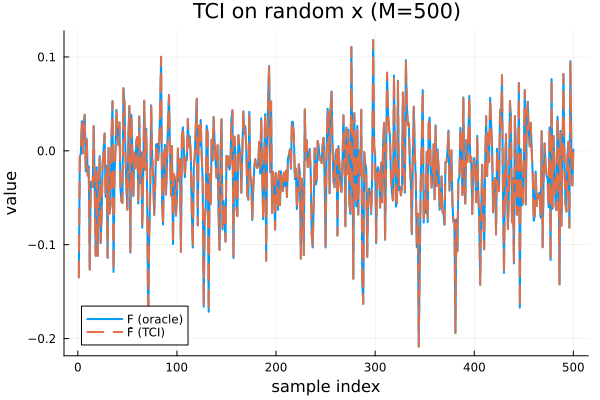

In [37]:
using .RandomTarget
using .FunctionTCI
import TensorCrossInterpolation as TCI

# Measure wall time of the block
using Dates
""" For test"""

###### Target function setting

L = 6
Dks = 1  # number of frequencies per site for basis construction
ωss = [2π.*rand(Dks) for _ in 1:L] # Should be known from the circuit

gammas = gamma_vals(ωss)
domain_range = 1 .+ (2*π ./ gammas )

phis = [x->x[i] for i in 1:L] # Basic pre-processing function which picks k'th element of input vector.
t = make_basis_vectors(ωss, phis)


# TCI grid: degree-1 trig per angle ⇒ M_sample[k] points
phys_dims = [2*length(ωss[i]) + 1 for i in 1:length(ωss)]
α = 2  #Integer
M_sample = α .* phys_dims

#a_vec_list = [(π/(2*length(ωss[k])))  .*collect(0:2*length(ωss[k])) for k in 1:L]
a_vec_list = [domain_range[k] .* rand(M_sample[k]) for k in 1:L]

target_χ = 8

#fq, true_cores_C = RandomTarget.make_random_fq(L, target_χ, phys_dims, t)
fq, fq_clean, =RandomTarget.make_random_fq_noisy(L,target_χ,phys_dims, t; delta = 0.000000001)

##########################


# Parameters for TCI
χ = 81
tolerance = 1e-8

# index → value wrapper for TCI
f_idx(id::Vector{Int}) = fq([ a_vec_list[p][id[p]] for p in 1:L ])

ctr = CounterWithLog(0, Dict{Tuple{Vararg{Int}},Float64}(), Vector{Vector{Int}}(), false)  # true = verbose logging
f_cached = counted_unique_with_log(f_idx, ctr)

dims = M_sample # relabeling of physical dimensions for TCI notation
start_time = now()
tci, ranks, errors = TCI.crossinterpolate2(
    Float64, f_cached, dims; pivotsearch = :full, tolerance=tolerance, maxbonddim=χ
)

println("Function evaluations used by TCI: ", ctr.n, "----Naive construction", prod(dims), "--- d^2χ^2L=",dims[1]^2*L*χ^2)
println("errors:: ", errors)
println("last error = ", isempty(errors) ? NaN : last(errors),
        "  (below tol? ", (isempty(errors) ? false : last(errors) < tolerance), ")")

println("\n=== BASIC PROPERTIES OF tci ===")
println("linkdims(tci)  = ", TCI.linkdims(tci))    # bond dims per link


# Convert to an explicit TensorTrain and list core shapes
tt = TCI.TensorTrain(tci)
cores_F = TCI.sitetensors(tt)
cores_C   = ttF_to_ttC(cores_F, ωss ; auxs = a_vec_list)


p_random, y_true_rand, y_hat_rand, Phis_rand, rel_error = compare_and_plot(fq_clean, cores_C, t, L; M=500, seed=1223)
display(p_random)
#savefig(p_random, "/Figs/Numerics/random_comparison_plot_$(χ).svg")

end_time = now()
println("\nElapsed time for this block: ", end_time - start_time)

In [38]:
using ITensors, ITensorMPS

# A is a Vector of 3D arrays: A[n] has size (Dl, d, Dr)
function mps_from_arrays(A::Vector{<:AbstractArray})
  N = length(A)

  # physical/site indices
  sites = [Index(size(A[n], 2), "Site,n=$n") for n in 1:N]

  # internal link indices (set by right dims of each tensor)
  links = [Index(size(A[n], 3), "Link,l=$n") for n in 1:N-1]

  psi = MPS(sites)
  for n in 1:N
    Dl, d, Dr = size(A[n])

    l = (n == 1) ? Index(Dl, "Link,l=0") : links[n-1]
    r = (n == N) ? Index(Dr, "Link,l=$N") : links[n]

    psi[n] = ITensor(A[n], l, sites[n], r)
  end
  return psi
end

psi = mps_from_arrays(cores_C)

# optional: set a clear gauge before truncation
orthogonalize!(psi, 1)

# compress all bonds
truncate!(psi; cutoff=1e-8, maxdim=200)


6-element MPS:
 ((dim=1|id=2|"Link,l=0"), (dim=3|id=147|"Site,n=1"), (dim=3|id=486|"Link,l=1"))
 ((dim=3|id=399|"Site,n=2"), (dim=8|id=969|"Link,l=2"), (dim=3|id=486|"Link,l=1"))
 ((dim=3|id=593|"Site,n=3"), (dim=12|id=977|"Link,l=3"), (dim=8|id=969|"Link,l=2"))
 ((dim=3|id=953|"Site,n=4"), (dim=8|id=557|"Link,l=4"), (dim=12|id=977|"Link,l=3"))
 ((dim=3|id=501|"Site,n=5"), (dim=3|id=652|"Link,l=5"), (dim=8|id=557|"Link,l=4"))
 ((dim=3|id=888|"Site,n=6"), (dim=1|id=300|"Link,l=6"), (dim=3|id=652|"Link,l=5"))

In [25]:
# Example: to get the value at (j₁, ..., j₁₂) = (1,1,2,2,1,1,2,1,1,2,1,2):
inds = rand(1:3, 12)
val = reduce(*, [core[:,inds[i],:] for (i,core) in enumerate(true_cores_C)])
println("MPS value at $inds is ", val[])

MPS value at [2, 2, 1, 1, 2, 3, 2, 1, 2, 2, 3, 2] is -0.0019426976475647641


RMSE = 0.022970225037102304, rel_RMSE = 0.9178708582752684, max |error| = 0.08903611441905847 over M=500 random points
RMSE = 0.01577194763658601, rel_RMSE = 0.8538811029892618, max |error| = 0.06842388348423638 over M=500 random points
RMSE = 0.01655067807493516, rel_RMSE = 0.9688155469880771, max |error| = 0.05849766802234578 over M=500 random points
RMSE = 0.023693897776629336, rel_RMSE = 0.9729356954072349, max |error| = 0.075169548246118 over M=500 random points
RMSE = 0.02557840247429841, rel_RMSE = 0.9206205223123183, max |error| = 0.10999725086615231 over M=500 random points
L=4, chi=2: mean_ctr_n=7437.2, mean_rel_error=0.9268247451944323, std_rel_error=0.04829308070388755
RMSE = 0.011022502695644507, rel_RMSE = 0.6064523806682616, max |error| = 0.03230003461307313 over M=500 random points
RMSE = 0.008114761995359593, rel_RMSE = 0.39157944277919443, max |error| = 0.0313260030380714 over M=500 random points
RMSE = 0.016392497528406054, rel_RMSE = 1.2860993645619743, max |error| 

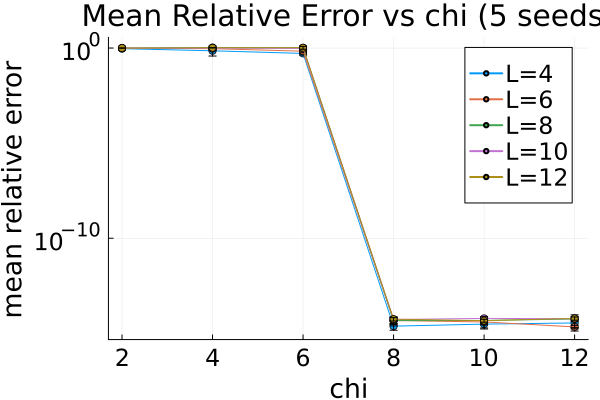

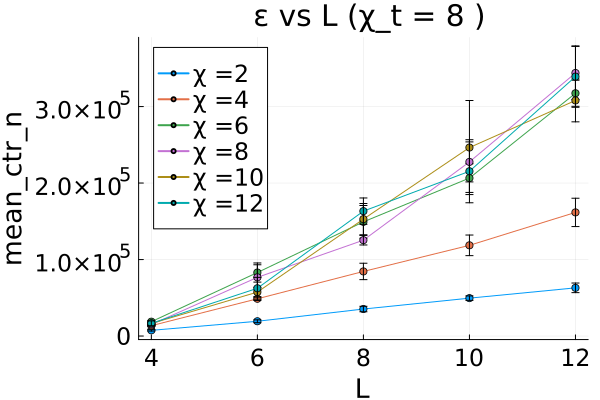

In [ ]:
"""For plot: Averaged relative error over 5 seeds"""

using Random
using Statistics
using Plots
using .FunctionTCI

L_vals = [4,6,8,10,12]
chi_vals = [2,4,6,8,10,12]
seeds = [1001, 1002, 1003, 1004, 1005]  # five independent seeds

# Will accumulate tuples of (L, chi, mean_ctr_n, std_ctr_n, mean_rel_error, std_rel_error)
results = NamedTuple{(:L, :chi, :mean_ctr_n, :std_ctr_n, :mean_rel_error, :std_rel_error)}[]

for L in L_vals
    
    for chi in chi_vals
        ctr_ns = Float64[]
        rel_errors = Float64[]

        for seed in seeds
            # Use the seed to randomize omega, fq, a_vec_list, and pivoting
            Random.seed!(seed + L * 1000 + chi * 10)  # unique seed per config and sweep

            Dks = 3
            ωss = [rand(Dks) for _ in 1:L]
            gammas = gamma_vals(ωss)
            domain_range = 1 .+ (2 * π ./ gammas)
            phys_dims = [2 * length(ωss[i]) + 1 for i in 1:length(ωss)]
            phis = [x -> x[i] for i in 1:L]
            t = make_basis_vectors(ωss, phis)

            target_chi = 8
            fq, true_cores_C = RandomTarget.make_random_fq(L, target_chi, phys_dims, t)

            α = 2
            M_sample = α .* phys_dims
            a_vec_list = [domain_range[k] .* rand(M_sample[k]) for k in 1:L]
            dims = M_sample

            f_idx(id::Vector{Int}) = fq([a_vec_list[p][id[p]] for p in 1:L])

            tolerance = 1e-8

            ctr = CounterWithLog(0, Dict{Tuple{Vararg{Int}},Float64}(), Vector{Vector{Int}}(), false)
            f_cached = counted_unique_with_log(f_idx, ctr)

            # Use distinct seed also for TCI pivots
            Random.seed!(seed + 10_000 + 100 * L + chi)

            tci, ranks, errors = TCI.crossinterpolate2(
                Float64, f_cached, dims; pivotsearch = :full, tolerance = tolerance, maxbonddim = chi
            )

            tt = TCI.TensorTrain(tci)
            cores_F = TCI.sitetensors(tt)
            cores_C = ttF_to_ttC(cores_F, ωss ; auxs = a_vec_list)

            _, _, _, _, rel_error = compare_and_plot(fq, cores_C, t, L; M=500, seed=1223)

            push!(ctr_ns, ctr.n)
            push!(rel_errors, rel_error)
        end

        mean_ctr_n = mean(ctr_ns)
        std_ctr_n = std(ctr_ns)
        mean_rel_error = mean(rel_errors)
        std_rel_error = std(rel_errors)
        push!(results, (; L = L, chi = chi, mean_ctr_n = mean_ctr_n, std_ctr_n = std_ctr_n,
                         mean_rel_error = mean_rel_error, std_rel_error = std_rel_error))
        println("L=$L, chi=$chi: mean_ctr_n=$(mean_ctr_n), mean_rel_error=$(mean_rel_error), std_rel_error=$(std_rel_error)")
    end
end

open("Datas/L_chi_results_avg.csv", "w") do io
    println(io, "L,chi,mean_ctr_n,std_ctr_n,mean_rel_error,std_rel_error")
    for r in results
        println(io, "$(r.L),$(r.chi),$(r.mean_ctr_n),$(r.std_ctr_n),$(r.mean_rel_error),$(r.std_rel_error)")
    end
end

# Plot mean relative error vs chi, error bars are std deviation, for all L
p = plot(
    xlabel = "chi",
    ylabel = "mean relative error",
    yscale = :log10,
    title = "Mean Relative Error vs chi (5 seeds)",
    legend = :topright,
    xticks = chi_vals,       # Ensure only integer chis appear on the x-axis
    xformatter = x -> string(Int(round(x))),  # Format x-tick labels as integers
)
for L in L_vals
    subset = sort(filter(r -> r.L == L, results); by = r -> r.chi)
    chis = [r.chi for r in subset]
    means = [r.mean_rel_error for r in subset]
    stds = [r.std_rel_error for r in subset]
    plot!(p, chis, means; yerror = stds, label = "L=$L", marker = :circle,
    guidefont = font(18),
    tickfont = font(16),
    legendfont = font(16),
    titlefont = font(20),)
end
savefig(p, "Figs/Numerics/mean_rel_error_vs_chi.svg")
display(p)

# --------- New Plot: mean_ctr_n vs L for each chi ---------
p2 = plot(
    xlabel = "L",
    ylabel = "mean_ctr_n",
    title = " ε vs L (χ_t = 8 )",
    legend = :topleft,
    marker = :circle,
    guidefont = font(18),
    tickfont = font(16),
    legendfont = font(16),
    titlefont = font(20),
)

for chi in chi_vals
    subset = sort(filter(r -> r.chi == chi, results); by = r -> r.L)
    Ls = [r.L for r in subset]
    mean_ctrs = [r.mean_ctr_n for r in subset]
    std_ctrs = [r.std_ctr_n for r in subset]
    plot!(p2, Ls, mean_ctrs; yerror=std_ctrs, label="χ =$chi", marker=:circle)
end
savefig(p2, "Figs/Numerics/mean_ctr_n_vs_L.svg")
display(p2)


In [ ]:
"""For plot: Averaged relative error over 5 seeds, NOISY"""

using Random
using Statistics
using Plots
using .FunctionTCI

L_vals = [4,6,8,10,12]
chi_vals = [2,4,6,8,10,12]
seeds = [1001, 1002, 1003, 1004, 1005]  # five independent seeds

M = 10000 # 1/M variance
delta = 1/M

# Will accumulate tuples of (L, chi, mean_ctr_n, std_ctr_n, mean_rel_error, std_rel_error)
results = NamedTuple{(:L, :chi, :mean_ctr_n, :std_ctr_n, :mean_rel_error, :std_rel_error)}[]

for L in L_vals
    
    for chi in chi_vals
        ctr_ns = Float64[]
        rel_errors = Float64[]

        for seed in seeds
            # Use the seed to randomize omega, fq, a_vec_list, and pivoting
            Random.seed!(seed + L * 1000 + chi * 10)  # unique seed per config and sweep

            Dks = 3
            ωss = [rand(Dks) for _ in 1:L]
            gammas = gamma_vals(ωss)
            domain_range = 1 .+ (2 * π ./ gammas)
            phys_dims = [2 * length(ωss[i]) + 1 for i in 1:length(ωss)]
            phis = [x -> x[i] for i in 1:L]
            t = make_basis_vectors(ωss, phis)

            target_chi = 8
            fq_noisy, fq, true_cores_C = RandomTarget.make_random_fq_noisy(L, target_chi, phys_dims, t; delta = delta, seed = seed)
            

            α = 2
            M_sample = α .* phys_dims
            a_vec_list = [domain_range[k] .* rand(M_sample[k]) for k in 1:L]
            dims = M_sample

            f_idx(id::Vector{Int}) = fq_noisy([a_vec_list[p][id[p]] for p in 1:L])

            tolerance = 1e-8

            ctr = CounterWithLog(0, Dict{Tuple{Vararg{Int}},Float64}(), Vector{Vector{Int}}(), false)
            f_cached = counted_unique_with_log(f_idx, ctr)

            # Use distinct seed also for TCI pivots
            Random.seed!(seed + 10_000 + 100 * L + chi)

            tci, ranks, errors = TCI.crossinterpolate2(
                Float64, f_cached, dims; pivotsearch = :full, tolerance = tolerance, maxbonddim = chi
            )

            tt = TCI.TensorTrain(tci)
            cores_F = TCI.sitetensors(tt)
            cores_C = ttF_to_ttC(cores_F, ωss ; auxs = a_vec_list)

            _, _, _, _, rel_error = compare_and_plot(fq, cores_C, t, L; M=500, seed=1223) # compare with true fq

            push!(ctr_ns, ctr.n)
            push!(rel_errors, rel_error)
        end

        mean_ctr_n = mean(ctr_ns)
        std_ctr_n = std(ctr_ns)
        mean_rel_error = mean(rel_errors)
        std_rel_error = std(rel_errors)
        push!(results, (; L = L, chi = chi, mean_ctr_n = mean_ctr_n, std_ctr_n = std_ctr_n,
                         mean_rel_error = mean_rel_error, std_rel_error = std_rel_error))
        println("L=$L, chi=$chi: mean_ctr_n=$(mean_ctr_n), mean_rel_error=$(mean_rel_error), std_rel_error=$(std_rel_error)")
    end
end

open("Datas/noisy/L_chi_results_avg.csv", "w") do io
    println(io, "L,chi,mean_ctr_n,std_ctr_n,mean_rel_error,std_rel_error")
    for r in results
        println(io, "$(r.L),$(r.chi),$(r.mean_ctr_n),$(r.std_ctr_n),$(r.mean_rel_error),$(r.std_rel_error)")
    end
end

# Plot mean relative error vs chi, error bars are std deviation, for all L
p = plot(
    xlabel = "chi",
    ylabel = "mean relative error",
    yscale = :log10,
    title = "Mean Relative Error vs chi (5 seeds)",
    legend = :topright,
    xticks = chi_vals,       # Ensure only integer chis appear on the x-axis
    xformatter = x -> string(Int(round(x))),  # Format x-tick labels as integers
)
for L in L_vals
    subset = sort(filter(r -> r.L == L, results); by = r -> r.chi)
    chis = [r.chi for r in subset]
    means = [r.mean_rel_error for r in subset]
    stds = [r.std_rel_error for r in subset]
    plot!(p, chis, means; yerror = stds, label = "L=$L", marker = :circle,
    guidefont = font(18),
    tickfont = font(16),
    legendfont = font(16),
    titlefont = font(20),)
end
savefig(p, "Figs/Numerics/noisy/mean_rel_error_vs_chi.svg")
display(p)

# --------- New Plot: mean_ctr_n vs L for each chi ---------
p2 = plot(
    xlabel = "L",
    ylabel = "mean_ctr_n",
    title = " ε vs L (χ_t = 8 )",
    legend = :topleft,
    marker = :circle,
    guidefont = font(18),
    tickfont = font(16),
    legendfont = font(16),
    titlefont = font(20),
)

for chi in chi_vals
    subset = sort(filter(r -> r.chi == chi, results); by = r -> r.L)
    Ls = [r.L for r in subset]
    mean_ctrs = [r.mean_ctr_n for r in subset]
    std_ctrs = [r.std_ctr_n for r in subset]
    plot!(p2, Ls, mean_ctrs; yerror=std_ctrs, label="χ =$chi", marker=:circle)
end
savefig(p2, "Figs/Numerics/noisy/mean_ctr_n_vs_L.svg")
display(p2)


In [7]:
"""
    build_fourier_series(N::Int, k::Real; rng=Random.GLOBAL_RNG)

Return `(f, terms)` where `f(x)` evaluates the N-variate Fourier series at
`x::AbstractVector` (length N). Frequencies ω are all binary vectors in {0,1}^N.
Coefficients scale as 1/‖ω‖^k. Zero-frequency term is excluded by default.
"""
function build_fourier_series(N::Int, D::Int, k::Real; rng=Random.GLOBAL_RNG)
    freqs = collect(Iterators.product(((-1:1) for _ in 1:N)...))
    terms = Vector{Any}()

    for ω_tuple in freqs
        ω = collect(ω_tuple)
        normω = sum(abs, ω)                 # one-norm of ω
        normω == 0 && continue               # skip zero frequency; add if you want a constant

        scale = 1.0 / normω^k
        # Random phase/sign to keep things generic; replace as needed
        c_cos = scale * (rand(rng) - 0.5) * 2
        c_sin = scale * (rand(rng) - 0.5) * 2

        push!(terms, (; ω, c_cos, c_sin))
    end

    f = function (x::AbstractVector)
        length(x) == N || throw(ArgumentError("x must have length $N"))
        s = 0.0
        @inbounds for t in terms
            phase = sum(t.ω[i] * x[i] for i in 1:N)
            s += t.c_cos * cos(phase) + t.c_sin * sin(phase)
        end
        return s
    end

    return f, terms
end
N = 10
k = 2
f, terms = build_fourier_series(N,3, k)
x = rand(N)  # point in [0,1]^3, for instance
val = f(x)
println("f(x) = $val")
println("First term: ", terms[1])


f(x) = 0.7483369209710296
First term: (ω = [-1, -1, -1, -1, -1, -1, -1, -1, -1, -1], c_cos = 0.008709201306864388, c_sin = 0.003630811975282995)


In [23]:
"""Run for a single designated kval and seed, show TCI.rank(tci) and rel_error."""

using Random
using Statistics
using Plots

N = 8
D = 1
ωss = [collect(1:D) for _ in 1:N]

basic_pre_process = [x->x[i] for i in 1:N]
basic_t = make_basis_vectors(ωss, basic_pre_process)

gammas = gamma_vals(ωss)
domain_range = 1 .+ (2*π ./ gammas )

phys_dims = [2*length(ωss[i]) + 1 for i in 1:length(ωss)]

α = 2  # Integer multiplier for TCI grid

# --- Designate the k and seed here ---
kval = 8   # pick a value from 2:8, for example
seed = 2   # pick a value from 1:M_SEEDS, for example
# --------------------------------------

println("\n==== k = $kval, seed = $seed ====")
Random.seed!(seed)

fq, terms = build_fourier_series(N, D, kval)

α = 2
M_sample = α .* phys_dims
a_vec_list = [domain_range[k] .* rand(M_sample[k]) for k in 1:N]
dims = M_sample

# index → value wrapper for TCI
f_idx(id::Vector{Int}) = fq([ a_vec_list[p][id[p]] for p in 1:N ])
ctr = CounterWithLog(0, Dict{Tuple{Vararg{Int}},Float64}(), Vector{Vector{Int}}(), false)
f_cached = counted_unique_with_log(f_idx, ctr)


# Cross interpolation
maxbonddim = 64
tolerance = 1e-8

tci, ranks, errors = TCI.crossinterpolate2(
    Float64, f_cached, dims; pivotsearch = :full, tolerance=tolerance, maxbonddim=maxbonddim
)

tt_rank = TCI.rank(tci)
println("tt_rank = $tt_rank")

# Build TT cores for error
tt = TCI.TensorTrain(tci)
cores_F = TCI.sitetensors(tt)
cores_C = ttF_to_ttC(cores_F, ωss ; auxs = a_vec_list)

phis = [x -> x[i] for i in 1:N]
t = make_basis_vectors(ωss, phis)

_, _, _, _, rel_err = compare_and_plot(fq, cores_C, t, N; M=100, seed=1223)


println("k = $kval, seed = $seed, rank = ", tt_rank, ", rel_error = ", rel_err)




==== k = 8, seed = 2 ====
tt_rank = 64
RMSE = 2.4402458899988394e-5, rel_RMSE = 1.2395448968471606e-5, max |error| = 0.00013173649832376455 over M=100 random points
k = 8, seed = 2, rank = 64, rel_error = 1.2395448968471606e-5



==== k = 2, seed = 1 ====
RMSE = 3.5187136167279593e-14, rel_RMSE = 1.0539457103523968e-14, max |error| = 1.2112533198660458e-13 over M=500 random points
k = 2, seed = 1, rank = 81, rel_err = 1.0539457103523968e-14, ctr.n = 135703

==== k = 2, seed = 2 ====
RMSE = 3.2710909058130275e-13, rel_RMSE = 9.26851167929009e-14, max |error| = 2.362998685612183e-12 over M=500 random points
k = 2, seed = 2, rank = 81, rel_err = 9.26851167929009e-14, ctr.n = 107362

==== k = 2, seed = 3 ====
RMSE = 6.361629987749561e-14, rel_RMSE = 2.0247441030072358e-14, max |error| = 4.605205106145149e-13 over M=500 random points
k = 2, seed = 3, rank = 81, rel_err = 2.0247441030072358e-14, ctr.n = 143437

==== k = 2, seed = 4 ====
RMSE = 6.20291667316093e-14, rel_RMSE = 1.7225107775555952e-14, max |error| = 3.1308289294429414e-13 over M=500 random points
k = 2, seed = 4, rank = 81, rel_err = 1.7225107775555952e-14, ctr.n = 125595

==== k = 2, seed = 5 ====
RMSE = 6.734170602919328e-14, rel_RMSE = 1.91650201743

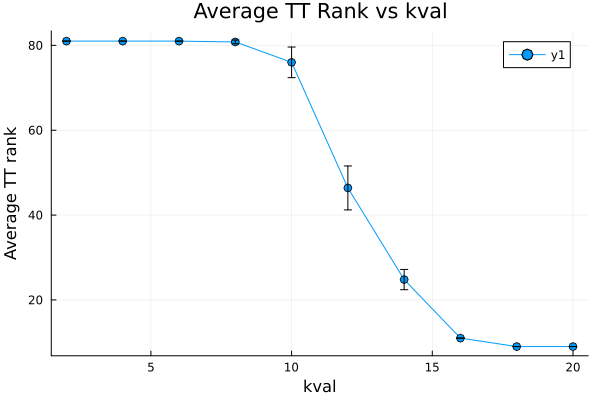

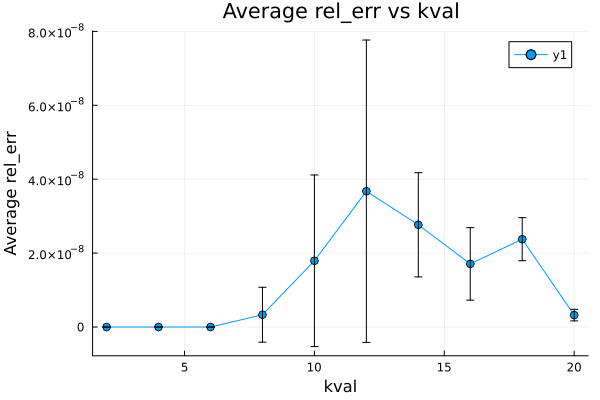

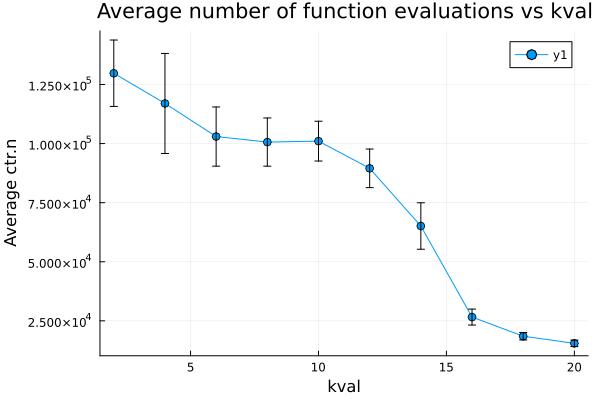

In [ ]:
using Random
using Statistics
using Plots

N = 8
D = 1
ωss = [collect(1:D) for _ in 1:N]

basic_pre_process = [x -> x[i] for i in 1:N]
basic_t = make_basis_vectors(ωss, basic_pre_process)

gammas = gamma_vals(ωss)
domain_range = 1 .+ (2 * π ./ gammas)

phys_dims = [2 * length(ωss[i]) + 1 for i in 1:length(ωss)]

α = 2  # Integer multiplier for TCI grid

kvals = 2:2:20
seeds = 1:5

mean_ctr_n = Float64[]
std_ctr_n = Float64[]
mean_tt_ranks = Float64[]
std_tt_ranks = Float64[]
mean_rel_errs = Float64[]
std_rel_errs = Float64[]

results = NamedTuple{(:kval, :mean_ctr_n, :std_ctr_n, :mean_tt_rank, :std_tt_rank, :mean_rel_err, :std_rel_err)}[]

for kval in kvals
    ctr_ns = Float64[]
    tt_ranks = Float64[]
    rel_errs = Float64[]

    for seed in seeds
        println("\n==== k = $kval, seed = $seed ====")
        Random.seed!(seed)

        fq, terms = build_fourier_series(N, D, kval)
        
        α = 2
        M_sample = α .* phys_dims
        a_vec_list = [domain_range[k] .* rand(M_sample[k]) for k in 1:N]
        dims = M_sample

        f_idx(id::Vector{Int}) = fq([a_vec_list[p][id[p]] for p in 1:N])
        ctr = CounterWithLog(0, Dict{Tuple{Vararg{Int}}, Float64}(), Vector{Vector{Int}}(), false)
        f_cached = counted_unique_with_log(f_idx, ctr)


        maxbonddim = 81
        tolerance = 1e-8

        tci, ranks, errors = TCI.crossinterpolate2(
            Float64, f_cached, dims; pivotsearch = :full, tolerance = tolerance, maxbonddim = maxbonddim
        )

        tt_rank = TCI.rank(tci)

        tt = TCI.TensorTrain(tci)
        cores_F = TCI.sitetensors(tt)
        cores_C = ttF_to_ttC(cores_F, ωss; auxs = a_vec_list)

        phis = [x -> x[i] for i in 1:N]
        t = make_basis_vectors(ωss, phis)

        _, _, _, _, rel_err = compare_and_plot(fq, cores_C, t, N; M=500, seed=1223)

        push!(ctr_ns, ctr.n)
        push!(tt_ranks, tt_rank)
        push!(rel_errs, rel_err)

        println("k = $kval, seed = $seed, rank = $tt_rank, rel_err = $rel_err, ctr.n = $(ctr.n)")
    end

    m_ctr = mean(ctr_ns); s_ctr = std(ctr_ns)
    m_rank = mean(tt_ranks); s_rank = std(tt_ranks)
    m_err = mean(rel_errs); s_err = std(rel_errs)

    push!(mean_ctr_n, m_ctr); push!(std_ctr_n, s_ctr)
    push!(mean_tt_ranks, m_rank); push!(std_tt_ranks, s_rank)
    push!(mean_rel_errs, m_err); push!(std_rel_errs, s_err)

    push!(results, (; kval = kval, mean_ctr_n = m_ctr, std_ctr_n = s_ctr,
                     mean_tt_rank = m_rank, std_tt_rank = s_rank,
                     mean_rel_err = m_err, std_rel_err = s_err))

    println("AVG k=$kval: mean_ctr_n=$m_ctr, mean_tt_rank=$m_rank, mean_rel_err=$m_err, errors=$errors")
end

# Save results
open("Datas/kval_avg_results.csv", "w") do io
    println(io, "kval,mean_ctr_n,std_ctr_n,mean_tt_rank,std_tt_rank,mean_rel_err,std_rel_err")
    for r in results
        println(io, "$(r.kval),$(r.mean_ctr_n),$(r.std_ctr_n),$(r.mean_tt_rank),$(r.std_tt_rank),$(r.mean_rel_err),$(r.std_rel_err)")
    end
end

# Plots
p1 = plot(kvals, mean_tt_ranks; yerror = std_tt_ranks, marker = :o,
    xlabel = "kval", ylabel = "Average TT rank", title = "Average TT Rank vs kval")
display(p1)
savefig(p1, "Figs/Numerics/average_tt_rank_vs_kval.png")

p2 = plot(kvals, mean_rel_errs; yerror = std_rel_errs, marker = :o,
    xlabel = "kval", ylabel = "Average rel_err", title = "Average rel_err vs kval")
display(p2)
savefig(p2, "Figs/Numerics/average_rel_err_vs_kval.png")

p3 = plot(kvals, mean_ctr_n; yerror = std_ctr_n, marker = :o,
    xlabel = "kval", ylabel = "Average ctr.n", title = "Average number of function evaluations vs kval")
display(p3)
savefig(p3, "Figs/Numerics/average_ctr_n_vs_kval.png")


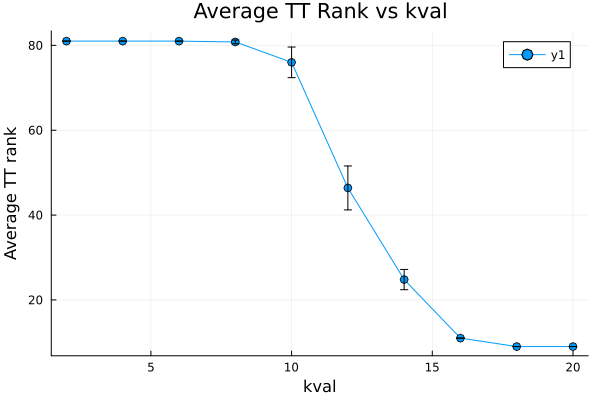

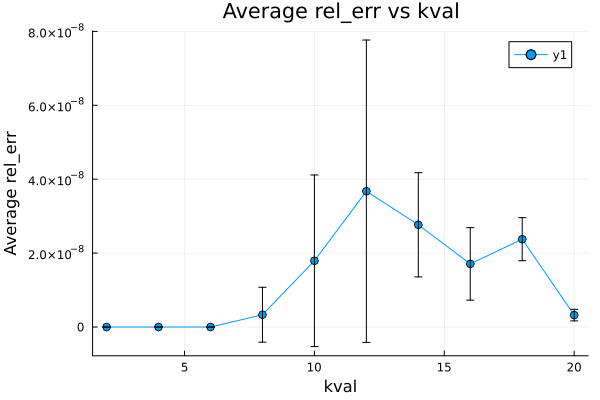

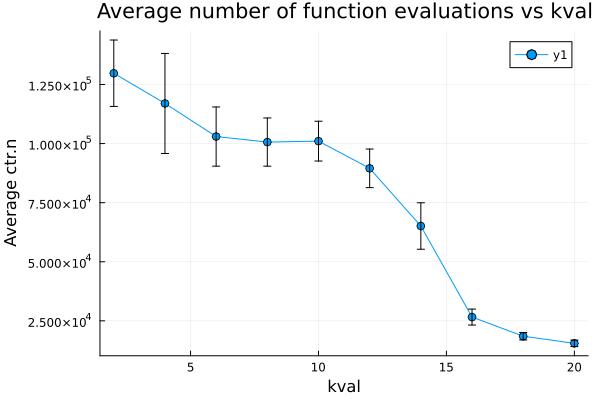

"./Figs/Numerics/average_ctr_n_vs_kval.svg"

In [27]:
p1 = plot(kvals, mean_tt_ranks; yerror = std_tt_ranks, marker = :o,
    xlabel = "kval", ylabel = "Average TT rank", title = "Average TT Rank vs kval")
display(p1)
savefig(p1, "Figs/Numerics/average_tt_rank_vs_kval.svg")

p2 = plot(kvals, mean_rel_errs; yerror = std_rel_errs, marker = :o,
    xlabel = "kval", ylabel = "Average rel_err", title = "Average rel_err vs kval")
display(p2)
savefig(p2, "Figs/Numerics/average_rel_err_vs_kval.svg")

p3 = plot(kvals, mean_ctr_n; yerror = std_ctr_n, marker = :o,
    xlabel = "kval", ylabel = "Average ctr.n", title = "Average number of function evaluations vs kval")
display(p3)
savefig(p3, "Figs/Numerics/average_ctr_n_vs_kval.svg")

In [ ]:
"""Repeat for multiple k and seeds, averaging TCI.rank(tci) and showing rel_error per combination."""

using Random
using Statistics
using Plots

N = 10
D = 1
ωss = [collect(1:D) for _ in 1:N]

basic_pre_process = [x->x[i] for i in 1:N]
basic_t = make_basis_vectors(ωss, basic_pre_process)

gammas = gamma_vals(ωss)
domain_range = 1 .+ (2*π ./ gammas )

phys_dims = [2*length(ωss[i]) + 1 for i in 1:length(ωss)]

α = 2   #Integer multiplier for TCI grid
M_SEEDS = 5
ks = 2:8

ranks_k = zeros(length(ks), M_SEEDS)
rel_errors_k = zeros(length(ks), M_SEEDS)

# Loop over k values and random seeds
for (ki, kval) in enumerate(ks)
    for seed in 1:M_SEEDS
        println("\n==== k = $kval, seed = $seed ====")
        Random.seed!(seed)
        
        fq, terms = build_fourier_series(N, D, kval)
        M_sample = α .* phys_dims
        a_vec_list = [domain_range[j] .* rand(M_sample[j]) for j in 1:N]
        
        # index → value wrapper for TCI
        f_idx(id::Vector{Int}) = fq([ a_vec_list[p][id[p]] for p in 1:N ])
        ctr = CounterWithLog(0, Dict{Tuple{Vararg{Int}},Float64}(), Vector{Vector{Int}}(), false)
        f_cached = counted_unique_with_log(f_idx, ctr)
        
        dims = M_sample

        # Cross interpolation
        maxbonddim = 64
        tolerance = 1e-8

        tci, ranks, errors = TCI.crossinterpolate2(
            Float64, f_cached, dims; pivotsearch = :full, tolerance=tolerance, maxbonddim=maxbonddim
        )

        # Save max bond dimension rank
        ranks_k[ki, seed] = TCI.rank(tci)

        # Build TT cores for error
        tt = TCI.TensorTrain(tci)
        cores_F = TCI.sitetensors(tt)

        try
            cores_C = ttF_to_ttC(cores_F, ωss; auxs=a_vec_list)
            # Estimate 2-norm relative error on grid (same as before)
            relF = relerr_grid_2norm(f_idx, dims, cores_F; nsamples=1000, seed=seed)
            rel_errors_k[ki, seed] = relF
        catch ex
            @warn "Error in ttF_to_ttC or relerr calculation: $ex"
            rel_errors_k[ki, seed] = NaN
        end

        println("k = $kval, seed = $seed, rank = ", ranks_k[ki,seed], ", rel_error = ", rel_errors_k[ki,seed])
    end
end

mean_ranks = [mean(ranks_k[i, :]) for i in 1:length(ks)]
std_ranks = [std(ranks_k[i, :]) for i in 1:length(ks)]
mean_relerrs = [mean(rel_errors_k[i, :], skipmissing=true) for i in 1:length(ks)]
std_relerrs = [std(rel_errors_k[i, :], skipmissing=true) for i in 1:length(ks)]

# Plot average TCI.rank(tci) vs k with std bars
plot(ks, mean_ranks; yerr=std_ranks, lw=3, marker=:o,
     xlabel="k (Fourier series decay parameter)",
     ylabel="Mean max-bond dim (TCI.rank)",
     label="Mean TCI.rank",
     title="Mean and std of TCI.rank vs k")
savefig("tci_rank_vs_k.png")
display(Plots.current())

# Plot rel_error (all per sample for each k)
scatter(ks, rel_errors_k'; xlabel="k", ylabel="rel_error", label="", legend=false, marker=:circle, title="Rel error for each seed, per k")
plot!(ks, mean_relerrs; lw=2, marker=:star, label="Mean relerr")
savefig("rel_error_vs_k.png")
display(Plots.current())

println("\nSummary (k, mean_rank, mean_rel_error):")
for (i, kval) in enumerate(ks)
    println("k = $(kval):  mean rank = $(mean_ranks[i]),  mean rel_error = $(mean_relerrs[i])")
end




==== k = 2, seed = 1 ====
k = 2, seed = 1, rank = 63.0, rel_error = 9.336419463562545e-15

==== k = 2, seed = 2 ====
k = 2, seed = 2, rank = 63.0, rel_error = 1.2007053828448285e-14

==== k = 2, seed = 3 ====
k = 2, seed = 3, rank = 63.0, rel_error = 7.955522177753419e-15

==== k = 2, seed = 4 ====


InterruptException: InterruptException:

In [ ]:
# Simple 1-layer neural network: n inputs -> 1 output
using Flux

n = 8  # set input dimension
model = Dense(n, 1)  # linear layer

# example forward pass
x = rand(Float32, n)
y = model(x)
y
